# Step 5 – Figures

Draws the manuscript and supplementary figures from the CSV files written by steps 1–4. No simulation is run here, except the single-index R0 runs if `R0_single_index.csv` is missing.

Each figure is saved twice in `results/figures/`:

- **TIFF** (LZW-compressed, 300 dpi by default) for submission. TIFF is a raster format, so it can't hold vector graphics; the resolution is set by `dpi`.
- **PDF** (vector) for editing and for journals that accept vector files.

| File | Content | Reviewer comment addressed |
| --- | --- | --- |
| `Fig2_reproduction_numbers` | R0 from one index cow (A) and early-outbreak reproduction number, days 1–15 (B) | R2.7–R2.9: βeff and the Eq. 11 R0 replaced by directly counted reproduction numbers; percentile intervals, no negative bounds |
| `Fig3_SEIR` | Exposed and infectious cows over one year, DM optimum | R1 Fig. 3: recovered cows removed; percentile bands |
| `Fig4_fit` | Simulated vs observed daily clinical cases | R1 Fig. 4, R2 minor 1: incidence of new infectious cows; β, γ, 1/σ, I₀ notation; each farm's own simulations |
| `Fig5_calibration` | Convergence (A), loss against parameter values (B), optima with near-optimal ranges (C) | R1 Fig. 5 caption; iteration counts consistent with Methods |
| `Fig6_sobol` | Total-order Sobol indices with bootstrap 95% CIs | R1 Fig. 6: one readable panel in the main text |
| `FigS_SEIR_PLF`, `FigS_recovered` | Fig. 3 for PLF; recovered cows | R1 Fig. 3 |
| `FigS_sobol_detail`, `FigS_sobol_convergence` | First- and total-order indices; indices against sample size | R1 Fig. 6; convergence check |
| `FigS_local_sensitivity` | Local sensitivity by farm | R1 Fig. 6, L385–395 |
| `FigS_prescreen` | Accepted pre-screen draws by farm and metric | Former Fig. S1 |

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import ab_sim as m
import common as c
import config as cfg

warnings.filterwarnings("ignore", category=RuntimeWarning)

RES = Path(cfg.OUTPUT_DIR)
OPT = RES / "optimization"
POST = RES / "post_simulations"
SENS = RES / "sensitivity"
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "legend.title_fontsize": 9,
    "legend.frameon": False,
    "pdf.fonttype": 42,          
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
})


METRIC_COLOURS = {"DM": "#1b9e9e", "PLF": "#e8483b"}          
FIT_COLOURS = dict(METRIC_COLOURS)                            
OBSERVED_COLOUR = "#4d4d4d"                                   # observed cases: dark grey                        
FARM_COLOURS = {"Farm1": "#00008b", "Farm2": "#a52a2a", "Farm3": "#006400", "Farm4": "#ff8c00"}
STATE_COLOURS = {"E": "#f5a000", "I": "#5dbb63", "R": "#c88fd0"}
OUTCOME_COLOURS = {"peak_daily_cases": STATE_COLOURS["I"],      # infectious green
                   "cumulative_cases": "#2e7d32",               # darker green
                   "cumulative_exposed": STATE_COLOURS["E"],    # exposed orange
                   "attack_rate": OBSERVED_COLOUR,              # observed grey
                   "final_recovered": STATE_COLOURS["R"],       # recovered plum
                   "outbreak_duration_days": "#9e9e9e"}         # light grey
METRIC_MARKERS = {"DM": "o", "PLF": "^"}

PARAM_LABELS = {"T": r"Transmission rate $\beta_{cow}$", "R": r"Recovery rate $\gamma_{cow}$ (day$^{-1}$)",
                "I": r"Incubation period $1/\sigma$ (days)", "IC": r"Index cows $I_0$",
                "HS": "Lactating herd size"}
PARAM_SHORT = {"T": r"$\beta_{cow}$", "R": r"$\gamma_{cow}$", "I": r"$1/\sigma$", "IC": r"$I_0$", "HS": "Herd size"}
METRIC_NAMES = {"DM": "DM (distance-based metric)", "PLF": "PLF (Poisson loss function)"}

OUTCOME_LABELS = {"peak_daily_cases": "Peak daily cases", "cumulative_cases": "Cumulative cases",
                  "cumulative_exposed": "Cumulative exposed", "attack_rate": "Attack rate",
                  "final_recovered": "Final recovered", "outbreak_duration_days": "Outbreak duration"}
METRIC_LABELS = {"DM": "DM", "PLF": "PLF"}

FARMS = list(cfg.FARM_LABELS.values())
METRICS = list(cfg.METRICS)

## Helper functions

In [3]:
def save(fig, name: str, dpi: int = 300) -> None:
    """Save a figure as LZW-compressed TIFF (raster, `dpi`) and as vector PDF."""
    fig.savefig(FIG / f"{name}.tiff", dpi=dpi, format="tiff",
                pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(FIG / f"{name}.pdf", format="pdf")
    print(f"saved {name}.tiff ({dpi} dpi) and {name}.pdf")

In [4]:
def panel_label(ax, letter: str, x: float = -0.12, y: float = 1.04) -> None:
    """Bold panel letter in the top-left corner, outside the axes."""
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=12, fontweight="bold",
            va="bottom", ha="left")

In [5]:
def boxed_border(ax) -> None:
    """Full black frame, as in the ggplot panel.border of the original figures."""
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.9)
        ax.spines[side].set_color("black")

In [6]:
def fmt_param(p: str, v: float) -> str:
    """Parameter value formatted for annotations."""
    if p == "T":
        return f"{v:.4f}"
    if p == "R":
        return f"{v:.3f}"
    return f"{int(round(v))}"

In [7]:
def near_optimal_table() -> pd.DataFrame:
    """Optimum and near-optimal range per farm, metric and parameter: optimiser evaluations whose
    loss is within 2 x the noise of one evaluation of the minimum (same rule as the step-1 cell).
    Uses the 2.5-97.5 percentiles, or min-max when fewer than 20 evaluations qualify."""
    hist = pd.read_csv(OPT / "bo_history.csv")
    hist = hist[hist.source == "optimiser"].copy()
    keys = ["farm", "metric", "run"]
    reev = pd.read_csv(OPT / "reevaluation.csv")
    noise = (reev.groupby(keys)["loss_reeval_per_sim_sd"].median()
             / np.sqrt(cfg.N_REPS_PER_EVAL)).rename("noise_sd").reset_index()
    hist = hist.merge(noise, on=keys, how="left")
    hist["best_loss"] = hist.groupby(keys)["loss"].transform("min")
    near = hist[hist["loss"] <= hist["best_loss"] + 2 * hist["noise_sd"]]
    rows = []
    for (farm, metric), g in near.groupby(["farm", "metric"]):
        for p in c.PARAMS:
            x = g[p]
            use_pct = len(x) >= 20
            rows.append({"farm": farm, "metric": metric, "parameter": p, "n": len(x),
                         "low": x.quantile(0.025) if use_pct else x.min(),
                         "high": x.quantile(0.975) if use_pct else x.max(),
                         "interval": "p2.5-p97.5" if use_pct else "min-max"})
    out = pd.DataFrame(rows)
    used = pd.read_csv(POST / "parameters_used.csv")
    opt_long = used.melt(id_vars=["farm", "metric"], value_vars=c.PARAMS,
                         var_name="parameter", value_name="optimum")
    return out.merge(opt_long, on=["farm", "metric", "parameter"], how="left")

In [8]:
def r0_single_index_table() -> pd.DataFrame:
    """R0 from one index cow per simulation. Reads R0_single_index.csv (written by the cell at
    the end of step 2) or, if missing, simulates it here with N_SIMULATIONS runs."""
    path = POST / "R0_single_index.csv"
    if path.exists():
        return pd.read_csv(path)
    print("R0_single_index.csv not found: simulating (one index cow per run)")
    farms = m.load_inputs(cfg)
    burns = c.farm_burn_ins(farms, verbose=False)
    used = pd.read_csv(POST / "parameters_used.csv")
    rows = []
    for r in used.itertuples():
        for s in range(cfg.N_SIMULATIONS):
            rng = np.random.default_rng(m.task_seed("r0_single", r.farm, r.metric, s))
            res = m.simulate(burns[r.farm], r.T, r.R, int(r.I), 1, 150, rng, cfg.SEED_PENS,
                             cfg.MASKED_PENS, cfg.ANNUAL_CULL_RATE, keep_infected=True)
            inf = res.infected
            rows.append({"farm": r.farm, "metric": r.metric, "sim": s,
                         "R0_single_index": int(inf.loc[inf.is_index, "secondary"].iloc[0])})
    out = pd.DataFrame(rows)
    out.to_csv(path, index=False)
    return out

In [9]:
def interval_summary(df: pd.DataFrame, value: str) -> pd.DataFrame:
    """Mean, median and 2.5/97.5 percentiles of `value` per farm and metric."""
    return (df.groupby(["farm", "metric"])[value]
              .agg(mean="mean", median="median",
                   low=lambda x: x.quantile(0.025), high=lambda x: x.quantile(0.975))
              .reset_index())

## Data

In [10]:
used = pd.read_csv(POST / "parameters_used.csv")
cases = pd.read_csv(POST / "case_incidence.csv")
herd_summary = pd.read_csv(POST / "herd_daily_summary.csv")
sim_summary = pd.read_csv(POST / "sim_summary.csv")
hist = pd.read_csv(OPT / "bo_history.csv")
sobol = pd.read_csv(SENS / "sobol_indices.csv")
local = pd.read_csv(SENS / "local_summary.csv")
observed = pd.read_csv(OPT / "observed_cases.csv")
near_opt = near_optimal_table()
r0_single = r0_single_index_table()
used

,farm,metric,run,T,R,I,IC,loss,loss_optimiser,infectious_period_days,duration_of_infection_days
0,Farm1,DM,0,0.001571,0.066749,1,1,213.181729,212.832264,14.981559,15.981559
1,Farm1,PLF,0,0.001571,0.066749,1,1,286.766172,222.665880,14.981559,15.981559
2,Farm2,DM,0,0.002210,0.079428,1,1,83.266364,74.070510,12.590053,13.590053
3,Farm2,PLF,0,0.000978,0.078151,1,8,181.341928,187.710372,12.795788,13.795788
4,Farm3,DM,0,0.002640,0.052711,1,5,204.497431,252.713439,18.971355,19.971355
5,Farm3,PLF,0,0.003757,0.077983,1,3,415.184024,379.797631,12.823373,13.823373
6,Farm4,DM,0,0.000577,0.079753,2,8,352.021465,319.734848,12.538764,14.538764
7,Farm4,PLF,0,0.000577,0.079753,2,8,237.881713,232.548211,12.538764,14.538764


## Figure 2 – Reproduction numbers

In [11]:
def plot_interval_panel(ax, summ: pd.DataFrame, xlabel: str, ref_line: float | None = 1.0) -> None:
    """Farms on the y axis, DM and PLF side by side: 2.5-97.5 percentile bar and a boxed mean label
    (the style of the original Fig. 2)."""
    offsets = {"DM": 0.18, "PLF": -0.18}
    for i, farm in enumerate(FARMS):
        for metric in METRICS:
            row = summ[(summ.farm == farm) & (summ.metric == metric)]
            if row.empty:
                continue
            r = row.iloc[0]
            y = len(FARMS) - 1 - i + offsets.get(metric, 0)
            col = METRIC_COLOURS[metric]
            ax.plot([r.low, r.high], [y, y], color=col, lw=1.4, solid_capstyle="butt")
            for xe in (r.low, r.high):
                ax.plot([xe, xe], [y - 0.07, y + 0.07], color=col, lw=1.4)
            ax.text(r["mean"], y, f"{r['mean']:.2f}", ha="center", va="center", fontsize=8,
                    fontweight="bold", color=col,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=col, lw=0.9))
    if ref_line is not None:
        ax.axvline(ref_line, color="grey", ls=":", lw=0.9)
    ax.set_yticks(range(len(FARMS)))
    ax.set_yticklabels(FARMS[::-1])
    ax.set_ylim(-0.6, len(FARMS) - 0.4)
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True, ls="--", lw=0.5, color="grey", alpha=0.6)
    ax.set_axisbelow(True)
    boxed_border(ax)

saved Fig2_reproduction_numbers.tiff (300 dpi) and Fig2_reproduction_numbers.pdf


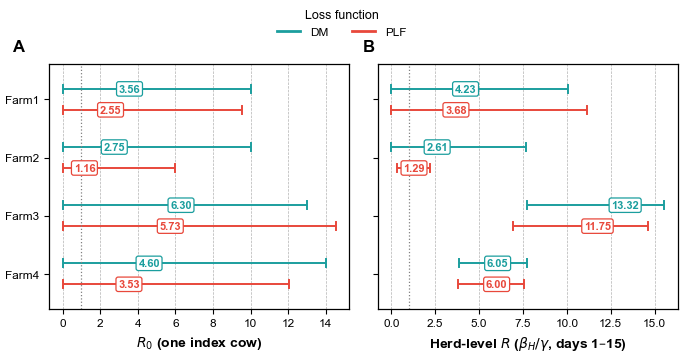

In [12]:
def figure2():
    r0 = interval_summary(r0_single, "R0_single_index")
    rh = interval_summary(sim_summary, "R0_H_d1_15")
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.4), sharey=True)
    plot_interval_panel(axes[0], r0, r"$R_0$ (one index cow)")
    plot_interval_panel(axes[1], rh, r"Herd-level $R$ ($\beta_H/\gamma$, days 1–15)")
    panel_label(axes[0], "A")
    panel_label(axes[1], "B", x=-0.05)
    handles = [Line2D([0], [0], color=METRIC_COLOURS[k], lw=2, label=METRIC_LABELS[k]) for k in METRICS]
    fig.legend(handles=handles, title="Loss function", loc="upper center", ncol=len(METRICS),
               bbox_to_anchor=(0.5, 1.08))
    fig.tight_layout()
    save(fig, "Fig2_reproduction_numbers", dpi=300)
    return fig

figure2();

## Figure 3 – Simulated exposed and infectious cows (one year)

saved Fig3_SEIR.tiff (300 dpi) and Fig3_SEIR.pdf


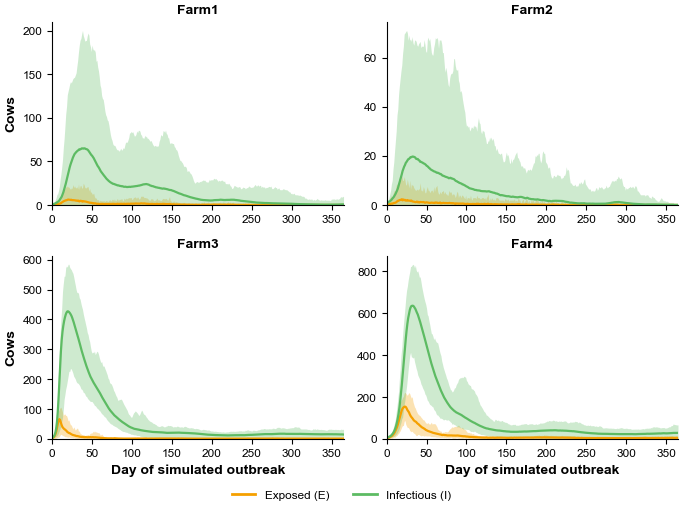

In [13]:
def plot_seir(metric: str, states: tuple, name: str, ylabel: str):
    """Mean (line) and 2.5-97.5 percentile band (shading) across simulations, one panel per farm."""
    fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.2))
    for ax, farm in zip(axes.flat, FARMS):
        d = herd_summary[(herd_summary.farm == farm) & (herd_summary.metric == metric)]
        for s in states:
            v = d[d.variable == s].sort_values("day")
            ax.fill_between(v.day, v.p2_5, v.p97_5, color=STATE_COLOURS[s], alpha=0.3, lw=0)
            ax.plot(v.day, v["mean"], color=STATE_COLOURS[s], lw=1.6)
        ax.set_title(farm)
        ax.set_xlim(0, d.day.max())
        ax.set_ylim(bottom=0)
    for ax in axes[1]:
        ax.set_xlabel("Day of simulated outbreak")
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    names = {"E": "Exposed (E)", "I": "Infectious (I)", "R": "Recovered (R)"}
    handles = [Line2D([0], [0], color=STATE_COLOURS[s], lw=2, label=names[s]) for s in states]
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.legend(handles=handles, loc="lower center", ncol=len(states), bbox_to_anchor=(0.5, 0.0))
    save(fig, name, dpi=300)
    return fig

plot_seir("DM", ("E", "I"), "Fig3_SEIR", "Cows");

## Figure 4 – Simulated vs observed daily clinical cases

In [14]:
METRIC_NAMES = {"DM": "DM (distance-based metric)", "PLF": "PLF (Poisson loss function)"}
TABLES = RES / "tables"
TABLES.mkdir(parents=True, exist_ok=True)


def save_table(df: pd.DataFrame, name: str, index: bool = False) -> pd.DataFrame:
    """Save a manuscript table as results_<name>.csv in results/tables/."""
    path = TABLES / f"results_{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")     # utf-8-sig so Excel shows β, γ, σ correctly
    print(f"saved {path.name}")
    return df


def parameter_table(include_ranges: bool = True) -> pd.DataFrame:
    """Optimal parameters per farm and loss function (one column each, e.g. "Farm1 DM"), with the
    near-optimal range in brackets when include_ranges=True. The range is widened to include the
    chosen optimum, which is near-optimal by construction (lowest re-evaluated loss)."""
    rows = [
        ("β_cow (per infectious–susceptible cow pair per day)", "T", lambda v: f"{v:.4f}"),
        ("γ_cow (per day)", "R", lambda v: f"{v:.3f}"),
        ("Infectious period 1/γ_cow (days)", "IP", lambda v: f"{v:.1f}"),
        ("Incubation period 1/σ (days)", "I", lambda v: f"{int(round(v))}"),
        ("Index cows I0", "IC", lambda v: f"{int(round(v))}"),
    ]
    out = {}
    for farm in FARMS:
        for mt in METRICS:
            col = []
            opt = used[(used.farm == farm) & (used.metric == mt)].iloc[0]
            rng_ = near_opt[(near_opt.farm == farm) & (near_opt.metric == mt)].set_index("parameter")
            for _, p, fmt in rows:
                if p == "IP":
                    val = 1 / opt["R"]
                    lo, hi = (1 / rng_.loc["R", "high"], 1 / rng_.loc["R", "low"]) if "R" in rng_.index else (np.nan, np.nan)
                else:
                    val = opt[p]
                    lo, hi = (rng_.loc[p, "low"], rng_.loc[p, "high"]) if p in rng_.index else (np.nan, np.nan)
                if np.isfinite(lo) and np.isfinite(hi):    # the chosen optimum is near-optimal too
                    lo, hi = min(lo, val), max(hi, val)
                txt = fmt(val)
                if include_ranges and np.isfinite(lo) and np.isfinite(hi):
                    txt += f" ({fmt(lo)}–{fmt(hi)})"
                col.append(txt)
            out[f"{farm} {mt}"] = col
    table = pd.DataFrame(out, index=[r[0] for r in rows])
    table.index.name = "Parameter"
    return table

saved Fig4_fit.tiff (300 dpi) and Fig4_fit.pdf


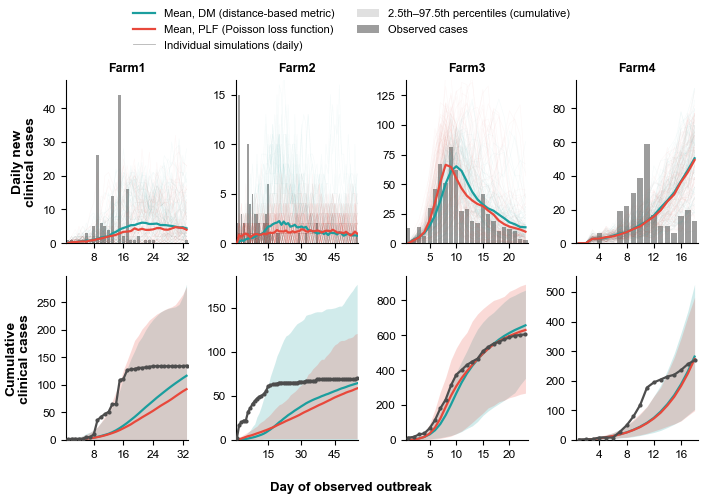

In [15]:
def figure4(line_alpha: float = 0.04, band: tuple = (0.025, 0.975), name: str = "Fig4_fit"):
    """Top row: observed daily cases (bars), every simulation (faint lines) and the simulated mean.
    Bottom row: observed cumulative cases (points) with the simulated mean and percentile band."""
    fig, axes = plt.subplots(2, len(FARMS), figsize=(7.2, 5.0))
    for j, farm in enumerate(FARMS):
        obs = observed[observed.farm == farm].sort_values("day")
        ndays = obs.day.max()
        ax, axc = axes[0, j], axes[1, j]
        ax.bar(obs.day, obs.observed, width=0.8, color=OBSERVED_COLOUR, alpha=0.55, lw=0, zorder=1)
        top = obs.observed.max()
        for metric in METRICS:
            col = FIT_COLOURS[metric]
            d = cases[(cases.farm == farm) & (cases.metric == metric) & (cases.day <= ndays)].sort_values("day")
            d = d.assign(cum=d.groupby("sim")["simulated"].cumsum())
            for _, s in d.groupby("sim"):
                ax.plot(s.day, s.simulated, color=col, lw=0.4, alpha=line_alpha, zorder=2)
            g, gc_ = d.groupby("day")["simulated"], d.groupby("day")["cum"]
            ax.plot(g.mean().index, g.mean().values, color=col, lw=1.6, zorder=3)
            axc.fill_between(gc_.mean().index, gc_.quantile(band[0]), gc_.quantile(band[1]),
                             color=col, alpha=0.2, lw=0, zorder=2)
            axc.plot(gc_.mean().index, gc_.mean().values, color=col, lw=1.6, zorder=3)
            top = max(top, g.quantile(0.975).max())
        axc.plot(obs.day, obs.observed.cumsum(), color=OBSERVED_COLOUR, lw=1.6, marker="o", ms=2, zorder=4)
        ax.set_ylim(0, top * 1.1)
        axc.set_ylim(bottom=0)
        ax.set_title(farm, fontsize=9)
        for a in (ax, axc):
            a.set_xlim(0.5, ndays + 0.5)
            a.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5, integer=True))
    axes[0, 0].set_ylabel("Daily new\nclinical cases")
    axes[1, 0].set_ylabel("Cumulative\nclinical cases")
    fig.supxlabel("Day of observed outbreak", fontsize=9.5, fontweight="bold")
    pct = f"{band[0] * 100:g}th–{band[1] * 100:g}th percentiles (cumulative)"
    handles = [Line2D([0], [0], color=FIT_COLOURS[mt], lw=1.6, label=f"Mean, {METRIC_NAMES[mt]}")
               for mt in METRICS]
    handles += [Line2D([0], [0], color="0.5", lw=0.6, alpha=0.6, label="Individual simulations (daily)"),
                Patch(facecolor="0.6", alpha=0.3, label=pct),
                Patch(facecolor=OBSERVED_COLOUR, alpha=0.55, label="Observed cases")]
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), fontsize=8)
    save(fig, name, dpi=300)
    return fig

figure4();

In [16]:
save_table(parameter_table(include_ranges=True), "Table_optimal_parameters", index=True)

saved results_Table_optimal_parameters.csv


,Farm1 DM,Farm1 PLF,Farm2 DM,Farm2 PLF,Farm3 DM,Farm3 PLF,Farm4 DM,Farm4 PLF
Parameter,,,,,,,,
β_cow (per infectious–susceptible cow pair per day),0.0016 (0.0007–0.0037),0.0016 (0.0007–0.0047),0.0022 (0.0008–0.0032),0.0010 (0.0007–0.0019),0.0026 (0.0019–0.0049),0.0038 (0.0018–0.0048),0.0006 (0.0005–0.0016),0.0006 (0.0005–0.0015)
γ_cow (per day),0.067 (0.042–0.080),0.067 (0.040–0.080),0.079 (0.040–0.079),0.078 (0.040–0.078),0.053 (0.040–0.080),0.078 (0.040–0.079),0.080 (0.041–0.080),0.080 (0.041–0.080)
Infectious period 1/γ_cow (days),15.0 (12.5–23.7),15.0 (12.5–24.9),12.6 (12.6–24.8),12.8 (12.8–24.8),19.0 (12.6–24.9),12.8 (12.6–24.9),12.5 (12.5–24.4),12.5 (12.5–24.4)
Incubation period 1/σ (days),1 (1–4),1 (1–4),1 (1–4),1 (1–1),1 (1–2),1 (1–2),2 (1–4),2 (1–3)
Index cows I0,1 (1–10),1 (1–10),1 (1–10),8 (1–10),5 (2–8),3 (2–10),8 (1–10),8 (1–10)


## Figure 5 – Calibration

In [17]:
def convergence_table() -> pd.DataFrame:
    """Best loss so far relative to the first evaluation, by evaluation, and the iteration of the
    last improvement (vertical line in panel A)."""
    h = hist[hist.run == hist.run.min()].sort_values(["farm", "metric", "evaluation"]).copy()
    h["best_relative"] = h.groupby(["farm", "metric"])["best_so_far"].transform(lambda s: s / s.iloc[0])
    return h

def last_improvement(h: pd.DataFrame) -> int:
    imp = h[h["best_so_far"].diff() < 0]
    return int(imp["iteration"].iloc[-1]) if len(imp) else int(h["iteration"].iloc[0])

In [18]:
def binned_loss(param: str, n_bins: int = 12) -> pd.DataFrame:
    """Loss scaled to 0-1 within each farm and metric, pooled across farms, in bins of the parameter:
    mean and 95% CI per bin (panel B)."""
    h = hist[hist.source == "optimiser"].copy()
    g = h.groupby(["farm", "metric"])["loss"]
    h["scaled_loss"] = (h["loss"] - g.transform("min")) / (g.transform("max") - g.transform("min"))
    lo, hi = cfg.BOUNDS[param]
    if param in cfg.INTEGER_PARAMS:
        h["bin"] = h[param].round().astype(int)
    elif param in cfg.LOG_SCALE_PARAMS:
        edges = np.geomspace(lo, hi, n_bins + 1)
        h["bin"] = pd.cut(h[param], edges, include_lowest=True).apply(lambda iv: np.sqrt(iv.left * iv.right))
    else:
        edges = np.linspace(lo, hi, n_bins + 1)
        h["bin"] = pd.cut(h[param], edges, include_lowest=True).apply(lambda iv: iv.mid)
    out = (h.groupby(["metric", "bin"], observed=True)["scaled_loss"]
             .agg(mean="mean", sd="std", n="count").reset_index())
    out["bin"] = out["bin"].astype(float)
    out["se"] = out["sd"] / np.sqrt(out["n"])
    out["low"] = out["mean"] - 1.96 * out["se"]
    out["high"] = out["mean"] + 1.96 * out["se"]
    return out[out.n >= 3]

In [19]:
def plot_optima(ax, param: str) -> None:
    """Optimum (marker) and near-optimal range (bar) by farm (colour) and metric (marker shape)."""
    offsets = {"DM": 0.15, "PLF": -0.15}
    d = near_opt[near_opt.parameter == param]
    for i, farm in enumerate(FARMS):
        for metric in METRICS:
            row = d[(d.farm == farm) & (d.metric == metric)]
            if row.empty:
                continue
            r = row.iloc[0]
            y = len(FARMS) - 1 - i + offsets.get(metric, 0)
            col = FARM_COLOURS.get(farm, "black")
            ax.plot([r.low, r.high], [y, y], color=col, lw=1.4,
                    ls="-" if metric == "DM" else "--")
            ax.plot(r.optimum, y, marker=METRIC_MARKERS[metric], color=col, ms=5, mec="white", mew=0.5)
    for b in cfg.BOUNDS[param]:
        ax.axvline(b, color="grey", ls=":", lw=0.8)
    if param in cfg.LOG_SCALE_PARAMS:
        ax.set_xscale("log")
    ax.set_yticks(range(len(FARMS)))
    ax.set_yticklabels(FARMS[::-1])
    ax.set_ylim(-0.6, len(FARMS) - 0.4)
    ax.set_xlabel(PARAM_LABELS[param], fontsize=9)
    ax.xaxis.grid(True, ls="--", lw=0.4, color="grey", alpha=0.5)
    ax.set_axisbelow(True)
    boxed_border(ax)

In [20]:
def baseline_loss() -> dict:
    """Loss of a flat curve at each farm's observed daily mean, per farm and metric.
    Relative loss = loss / baseline: 0 = perfect fit, 1 = no better than a flat line."""
    out = {}
    for farm in FARMS:
        obs = observed[observed.farm == farm].sort_values("day")["observed"].to_numpy(float)
        flat = np.full(obs.size, obs.mean())
        for mt in METRICS:
            out[(farm, mt)] = m.loss(mt, flat, obs, cfg)
    return out

def binned_relative_loss(param: str, base: dict, n_bins: int = 10) -> pd.DataFrame:
    """Relative loss of every pre-screen draw (uniform over the prior, so all values are covered),
    pooled across farms, in bins of the parameter: mean and 95% CI per bin and metric."""
    dr = pd.read_csv(OPT / "prescreen_draws.csv")
    rows = []
    for mt in METRICS:
        rel = dr[f"loss_{mt}"] / dr["farm"].map(lambda f: base[(f, mt)])
        x = dr[param]
        lo, hi = cfg.BOUNDS[param]
        if param in cfg.INTEGER_PARAMS:
            bins = x.round().astype(int)
        else:
            edges = (np.geomspace(lo, hi, n_bins + 1) if param in cfg.LOG_SCALE_PARAMS
                     else np.linspace(lo, hi, n_bins + 1))
            idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
            centres = (np.sqrt(edges[:-1] * edges[1:]) if param in cfg.LOG_SCALE_PARAMS
                       else (edges[:-1] + edges[1:]) / 2)
            bins = pd.Series(centres[idx], index=x.index)
        g = pd.DataFrame({"bin": bins, "rel": rel}).groupby("bin")["rel"]
        s = g.agg(mean="mean", sd="std", n="count").reset_index()
        s["low"] = s["mean"] - 1.96 * s["sd"] / np.sqrt(s["n"])
        s["high"] = s["mean"] + 1.96 * s["sd"] / np.sqrt(s["n"])
        s["metric"] = mt
        rows.append(s[s.n >= 3])
    return pd.concat(rows)

saved Fig5_loss_vs_parameters.tiff (300 dpi) and Fig5_loss_vs_parameters.pdf


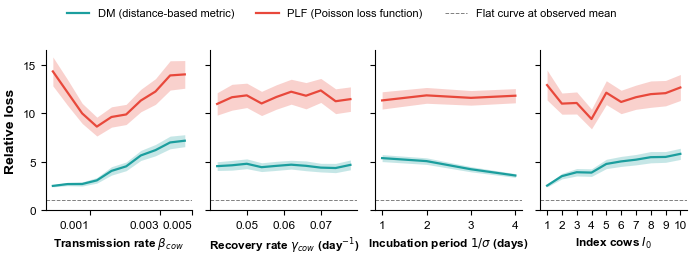

In [21]:
def figure5():
    """Relative loss of all pre-screen draws against each parameter, pooled across farms."""
    base = baseline_loss()
    fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.7), sharey=True)
    for ax, p in zip(axes, c.PARAMS):
        b = binned_relative_loss(p, base)
        for mt in METRICS:
            s = b[b.metric == mt]
            ax.fill_between(s["bin"], s["low"], s["high"], color=METRIC_COLOURS[mt], alpha=0.25, lw=0)
            ax.plot(s["bin"], s["mean"], color=METRIC_COLOURS[mt], lw=1.6)
        if p in cfg.LOG_SCALE_PARAMS:
            ax.set_xscale("log")
            lo, hi = cfg.BOUNDS[p]
            ax.set_xlim(lo, hi)
            ticks = [0.001, 0.003, 0.005]          # edit to taste
            ax.xaxis.set_major_locator(mpl.ticker.FixedLocator(ticks))
            ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
            ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
#             ax.tick_params(axis="x", labelrotation=45)
            for lab in ax.get_xticklabels():
                lab.set_horizontalalignment("right")
        if p in cfg.INTEGER_PARAMS:
            ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
        ax.axhline(1, color="grey", ls="--", lw=0.7)
        ax.set_xlabel(PARAM_LABELS[p], fontsize=8.5)
    axes[0].set_ylabel("Relative loss")
    axes[0].set_ylim(bottom=0)
    handles = [Line2D([0], [0], color=METRIC_COLOURS[mt], lw=1.6, label=METRIC_NAMES[mt]) for mt in METRICS]
    handles.append(Line2D([0], [0], color="grey", ls="--", lw=0.7, label="Flat curve at observed mean"))
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0), fontsize=8)
    save(fig, "Fig5_loss_vs_parameters", dpi=300)
    return fig

figure5();

## Figure 6 – Sobol total-order indices (main text)

saved Fig6_sobol.tiff (300 dpi) and Fig6_sobol.pdf


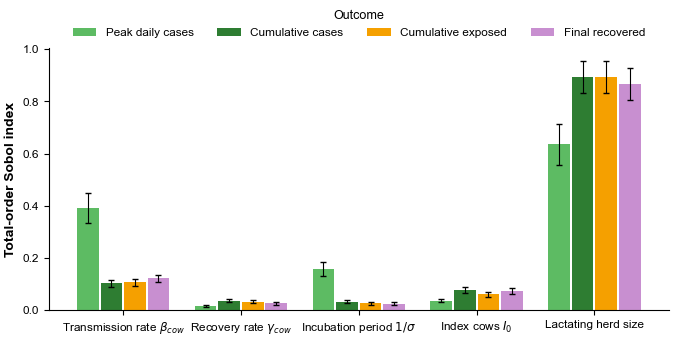

In [28]:
def figure6(outcomes=("peak_daily_cases", "cumulative_cases", "cumulative_exposed", "attack_rate")):
    """Total-order Sobol indices with bootstrap 95% CIs at the largest sample size."""
    s = sobol[sobol.N == sobol.N.max()]
    params = ["T", "R", "I", "IC", "HS"]
    width = 0.8 / len(outcomes)
    fig, ax = plt.subplots(figsize=(8.0, 3.4))
    for k, o in enumerate(outcomes):
        d = s[s.outcome == o].set_index("parameter").reindex(params)
        x = np.arange(len(params)) - 0.4 + width * (k + 0.5)
        ax.bar(x, d["ST"], width=width * 0.92, color=OUTCOME_COLOURS[o], label=OUTCOME_LABELS[o])
        ax.errorbar(x, d["ST"], yerr=d["ST_conf95"], fmt="none", ecolor="black", elinewidth=0.8, capsize=2)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(range(len(params)))
    ax.set_xticklabels([PARAM_LABELS[p].replace(" (days)", "").replace(" (day$^{-1}$)", "") for p in params],
                       fontsize=8.5)
    ax.set_ylabel("Total-order Sobol index")
    ax.set_ylim(bottom=min(0, (s["ST"] - s["ST_conf95"]).min() * 1.1))
    ax.legend(title="Outcome", ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    save(fig, "Fig6_sobol", dpi=300)
    return fig

figure6(outcomes=("peak_daily_cases", "cumulative_cases", "cumulative_exposed", "final_recovered"));

## Supplementary figures

saved FigS_SEIR_PLF.tiff (300 dpi) and FigS_SEIR_PLF.pdf
saved FigS_recovered_DM.tiff (300 dpi) and FigS_recovered_DM.pdf


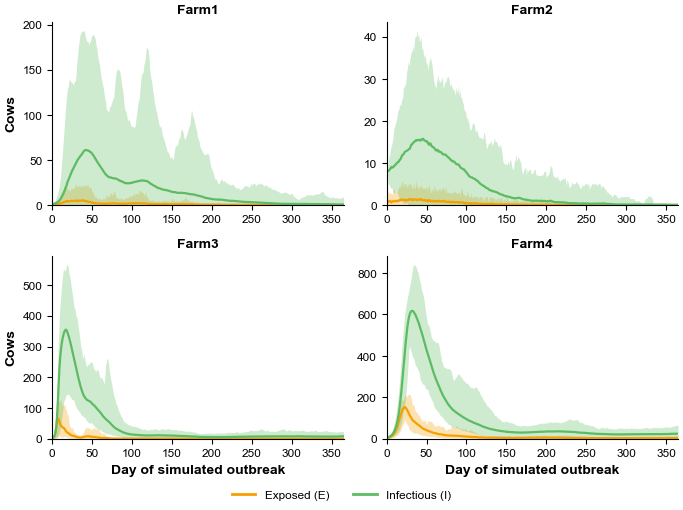

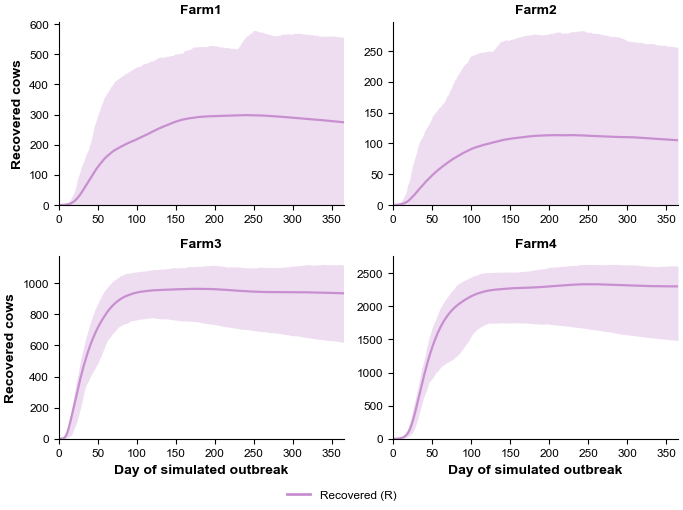

In [23]:
plot_seir("PLF", ("E", "I"), "FigS_SEIR_PLF", "Cows");
plot_seir("DM", ("R",), "FigS_recovered_DM", "Recovered cows");

saved FigS_sobol_detail.tiff (300 dpi) and FigS_sobol_detail.pdf


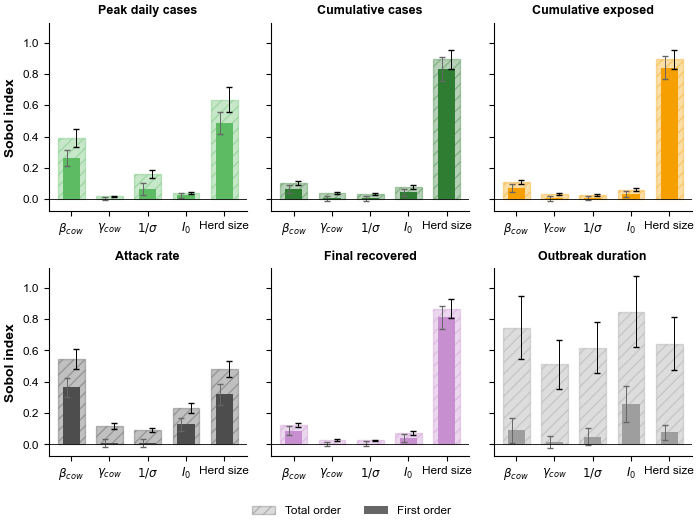

In [24]:
def figure_sobol_detail():
    """First-order (solid) and total-order (hatched) indices with 95% CIs, one panel per outcome."""
    s = sobol[sobol.N == sobol.N.max()]
    params = ["T", "R", "I", "IC", "HS"]
    outcomes = [o for o in OUTCOME_LABELS if o in s.outcome.unique()]
    ncol = 3
    nrow = int(np.ceil(len(outcomes) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.2, 2.6 * nrow), sharey=True)
    for ax, o in zip(axes.flat, outcomes):
        d = s[s.outcome == o].set_index("parameter").reindex(params)
        x = np.arange(len(params))
        ax.bar(x, d["ST"], width=0.7, color=OUTCOME_COLOURS[o], alpha=0.35, hatch="///",
               edgecolor=OUTCOME_COLOURS[o], label="Total order")
        ax.bar(x, d["S1"], width=0.45, color=OUTCOME_COLOURS[o], label="First order")
        ax.errorbar(x + 0.12, d["ST"], yerr=d["ST_conf95"], fmt="none", ecolor="black", elinewidth=0.7, capsize=2)
        ax.errorbar(x - 0.12, d["S1"], yerr=d["S1_conf95"], fmt="none", ecolor="0.4", elinewidth=0.7, capsize=2)
        ax.axhline(0, color="black", lw=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels([PARAM_SHORT[p] for p in params])
        ax.set_title(OUTCOME_LABELS[o], fontsize=9)
    for ax in list(axes.flat)[len(outcomes):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("Sobol index")
    handles = [Patch(facecolor="0.6", alpha=0.35, hatch="///", edgecolor="0.4", label="Total order"),
               Patch(facecolor="0.4", label="First order")]
    fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save(fig, "FigS_sobol_detail", dpi=300)
    return fig

figure_sobol_detail();

saved FigS_sobol_convergence.tiff (300 dpi) and FigS_sobol_convergence.pdf


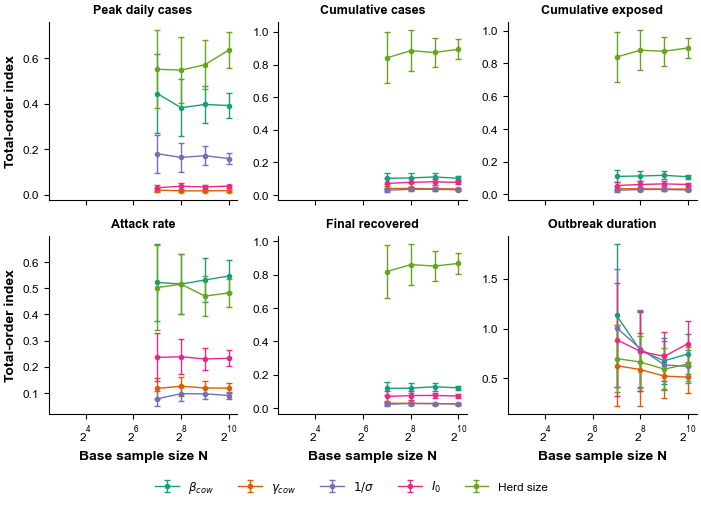

In [25]:
def figure_sobol_convergence():
    """Total-order indices (with 95% CIs) against the base sample size N."""
    params = ["T", "R", "I", "IC", "HS"]
    pcol = {"T": "#1b9e77", "R": "#d95f02", "I": "#7570b3", "IC": "#e7298a", "HS": "#66a61e"}
    outcomes = [o for o in OUTCOME_LABELS if o in sobol.outcome.unique()]
    ncol = 3
    nrow = int(np.ceil(len(outcomes) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.2, 2.5 * nrow), sharex=True)
    for ax, o in zip(axes.flat, outcomes):
        for p in params:
            d = sobol[(sobol.outcome == o) & (sobol.parameter == p)].sort_values("N")
            ax.errorbar(d.N, d.ST, yerr=d.ST_conf95, color=pcol[p], marker="o", ms=3, lw=1, capsize=2,
                        label=PARAM_SHORT[p])
        ax.set_xscale("log", base=2)
        ax.set_title(OUTCOME_LABELS[o], fontsize=9)
    for ax in list(axes.flat)[len(outcomes):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("Base sample size N")
    for ax in axes[:, 0]:
        ax.set_ylabel("Total-order index")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save(fig, "FigS_sobol_convergence", dpi=300)
    return fig

figure_sobol_convergence();

saved FigS_local_sensitivity.tiff (300 dpi) and FigS_local_sensitivity.pdf


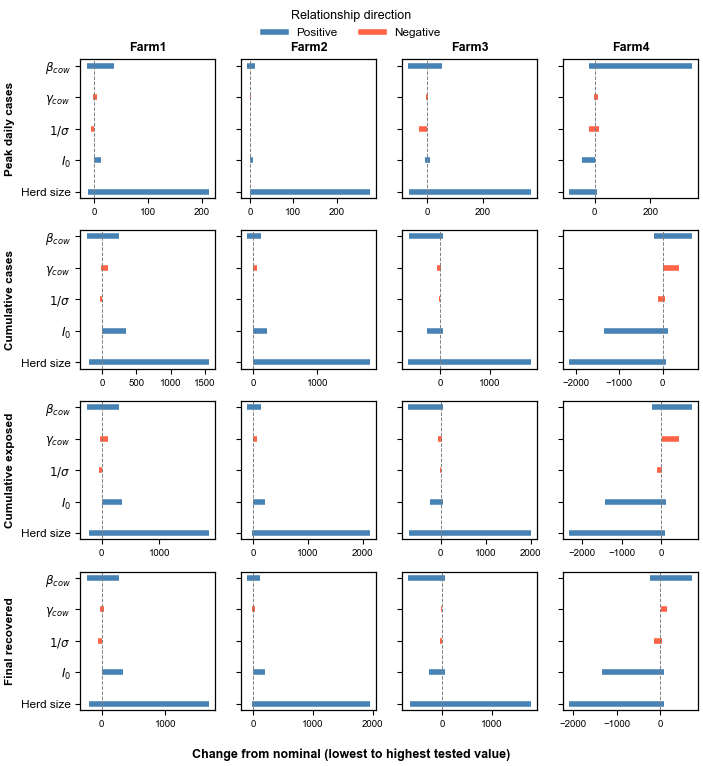

In [26]:
def figure_local(outcomes=("peak_daily_cases", "cumulative_cases", "cumulative_exposed", "final_recovered")):
    """Tornado plot as in the original Fig. 6A: for each farm, outcome and parameter, the paired
    change from nominal at the lowest and highest tested value (bar), coloured by whether the outcome
    increases (positive) or decreases (negative) with the parameter."""
    params = ["T", "R", "I", "IC", "HS"]
    fig, axes = plt.subplots(len(outcomes), len(FARMS), figsize=(7.2, 1.7 * len(outcomes) + 0.6),
                             sharey=True)
    for i, o in enumerate(outcomes):
        for j, farm in enumerate(FARMS):
            ax = axes[i, j]
            for k, p in enumerate(params):
                d = local[(local.farm == farm) & (local.outcome == o) & (local.parameter == p)].sort_values("value")
                if d.empty:
                    continue
                lo, hi = d["diff_mean"].iloc[0], d["diff_mean"].iloc[-1]
                col = "steelblue" if hi >= lo else "tomato"
                y = len(params) - 1 - k
                ax.plot([lo, hi], [y, y], color=col, lw=4, solid_capstyle="butt")
            ax.axvline(0, color="grey", ls="--", lw=0.7)
            ax.set_yticks(range(len(params)))
            ax.set_yticklabels([PARAM_SHORT[p] for p in params[::-1]])
            boxed_border(ax)
            if i == 0:
                ax.set_title(farm, fontsize=9)
            if j == 0:
                ax.set_ylabel(OUTCOME_LABELS[o], fontsize=8.5)
            ax.tick_params(axis="x", labelsize=7)
    fig.supxlabel("Change from nominal (lowest to highest tested value)", fontsize=9, fontweight="bold")
    handles = [Line2D([0], [0], color="steelblue", lw=4, label="Positive"),
               Line2D([0], [0], color="tomato", lw=4, label="Negative")]
    fig.legend(handles=handles, title="Relationship direction", loc="upper center", ncol=2,
               bbox_to_anchor=(0.5, 1.04))
    fig.tight_layout()
    save(fig, "FigS_local_sensitivity", dpi=300)
    return fig

figure_local();

saved FigS_prescreen.tiff (300 dpi) and FigS_prescreen.pdf


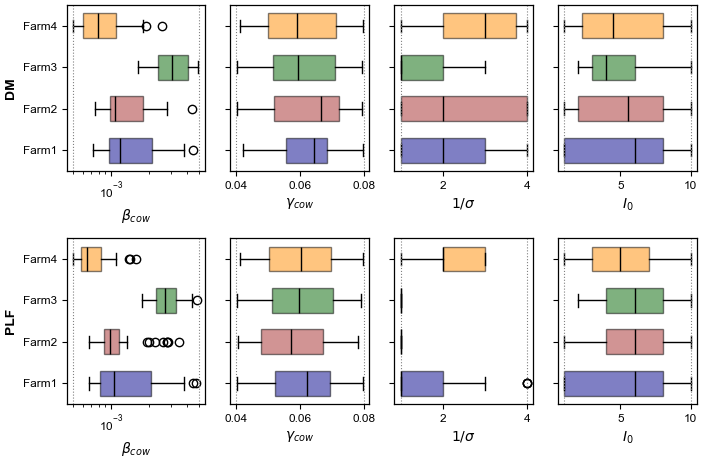

In [27]:
def figure_prescreen():
    """Accepted pre-screen (rejection ABC) draws: distribution of each parameter by farm and metric,
    with prior bounds (dotted)."""
    acc = pd.read_csv(OPT / "prescreen_accepted.csv")
    fig, axes = plt.subplots(len(METRICS), 4, figsize=(7.2, 2.4 * len(METRICS)))
    axes = np.atleast_2d(axes)
    for i, metric in enumerate(METRICS):
        for j, p in enumerate(c.PARAMS):
            ax = axes[i, j]
            data = [acc[(acc.metric == metric) & (acc.farm == f)][p].values for f in FARMS]
            bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
                            medianprops=dict(color="black", lw=1))
            for patch, f in zip(bp["boxes"], FARMS):
                patch.set_facecolor(FARM_COLOURS[f])
                patch.set_alpha(0.5)
            for b in cfg.BOUNDS[p]:
                ax.axvline(b, color="grey", ls=":", lw=0.8)
            if p in cfg.LOG_SCALE_PARAMS:
                ax.set_xscale("log")
            ax.set_yticks(range(1, len(FARMS) + 1))
            ax.set_yticklabels(FARMS if j == 0 else [])
            ax.set_xlabel(PARAM_SHORT[p])
            boxed_border(ax)
        axes[i, 0].set_ylabel(metric)
    fig.tight_layout()
    save(fig, "FigS_prescreen", dpi=300)
    return fig

figure_prescreen();

## Captions (draft)

**Figure 2.** Reproduction numbers estimated from the calibrated model for each farm and loss function (DM, distance-based metric; PLF, Poisson loss function). (A) Basic reproduction number R0: number of cows exposed by a single infectious index cow introduced into a fully susceptible herd, simulated with each farm's optimal parameters. (B) Early-outbreak reproduction number: mean number of cows exposed by each cow that became infectious during days 1–15 of the simulated outbreak. Labels show the mean across 100 simulations; bars show the 2.5th–97.5th percentiles. Dotted line: reproduction number of 1.

**Figure 3.** Simulated numbers of exposed (E) and infectious (I) cows over one year on each farm, using the parameters optimised with the distance-based metric. Lines show the mean and shading the 2.5th–97.5th percentiles of 100 simulations. Infectious cows were introduced only on day 1; later increases arise from susceptible replacement heifers entering the lactating pens. Recovered cows and the PLF-based results are shown in Supplementary Figures S_.

**Figure 4.** Daily new clinical cases observed on each farm (brown points) and simulated with the parameters optimised using the distance-based metric (DM, blue) and the Poisson loss function (PLF, purple). Simulated cases are cows becoming infectious in the four milking pens. Faint lines show individual simulations (n = 100) and dashed lines their mean. Boxes give the optimal transmission probability β (per infectious–susceptible pair per day), recovery rate γ (per day), latent period 1/σ (days) and number of index cows I0 for DM and PLF.

**Figure 5.** Calibration of the agent-based model by Bayesian optimisation. (A) Best loss found so far, relative to the first evaluation, by optimiser iteration for each farm (iterations ≤ 0 are the pre-screen points given to the optimiser); dashed lines mark the last improvement. (B) Loss, scaled to 0–1 within each farm and loss function, against parameter values tried by the optimiser, pooled across farms; lines show bin means and shading their 95% CIs. (C) Optimal parameter values (markers) and the range of values whose loss was within two standard deviations of simulation noise of the minimum (bars), by farm and loss function. Dotted lines mark the search bounds.

**Figure 6.** Total-order Sobol sensitivity indices of four outbreak outcomes over 100 days to transmission probability β, recovery rate γ, latent period 1/σ, number of index cows I0 and lactating herd size. Error bars show bootstrap 95% confidence intervals. First-order indices, the remaining outcomes, convergence with sample size and the local sensitivity analysis are in Supplementary Figures S_.